# <p style="width: 100%; box-sizing: border-box; min-height: 180px; height: auto; display: flex; align-items: center; justify-content: center; border-radius: 0px; border: 6px solid #D4AF37; padding: 40px 30px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.5; margin-bottom: 10px;">💳🔍 Predicting Credit Card Fraud: Uncover Fraudulent Transactions with Machine Learning! 🏆</p>

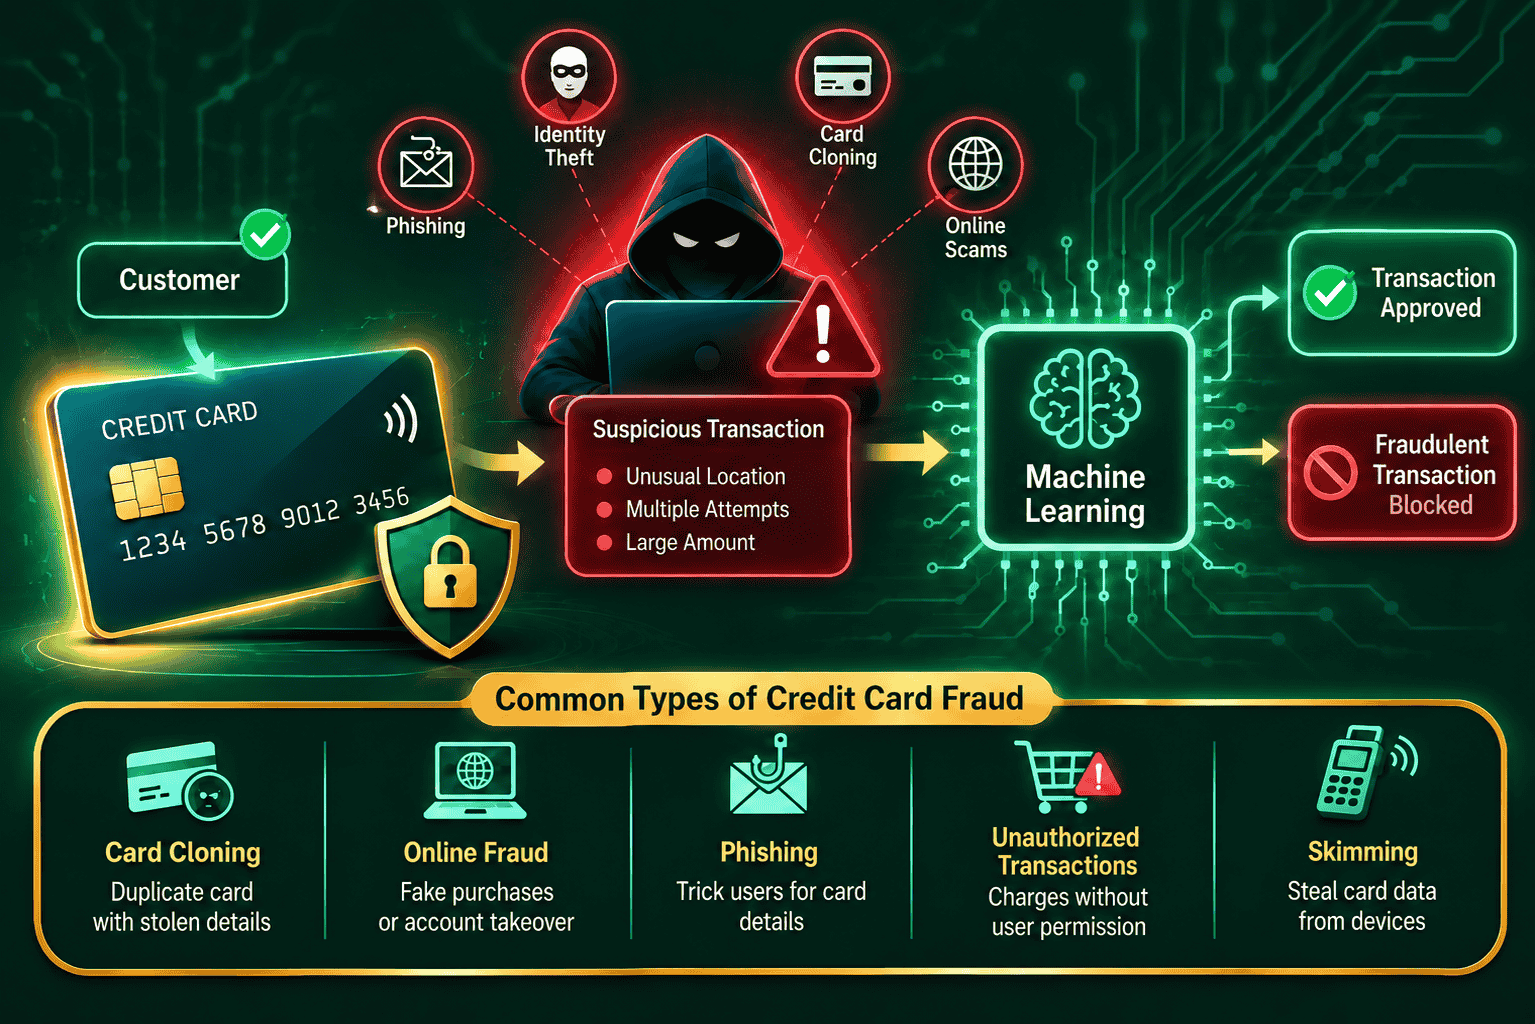

# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">Import Libraries</p>

In [1]:
# import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import time
import gc
import os
import glob
import random
import shutil
import time
from itertools import combinations
import sys
import html
from IPython.display import display, HTML
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from contextlib import contextmanager
from sklearn.metrics import average_precision_score
from sklearn.metrics import roc_auc_score
# ignore warnings
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)

# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">Competition Dataset Loading & Data Exploration</p>

<div style="width:100%; box-sizing:border-box; background-color:#E8F0E8; padding:18px; border:1px solid #D4AF37; border-radius:10px;">
    <h2 style="background-color:#18352F; color:#FFE5A0; padding:15px; border:2px solid #D4AF37; border-radius:8px; text-align:center; margin-top:0;">
        DATASET DESCRIPTION
    </h2>
    <h3 style="color:#285044; margin-top:20px;">
        Understanding the Data
    </h3>
    <p style="color:#285044; font-size:14px; line-height:1.7;">
        This dataset contains the credit card transaction records used to build
        a model for fraudulent transaction detection.
        Each record represents a transaction with features that describes
        transaction characteristics, account information, customer behaviour,
        and risk-related indicators.
    </p>
    <h3 style="color:#285044; margin-top:20px;">
        Dataset Files
    </h3>
    <div style="width:100%; overflow-x:auto;">
        <table style="width:100%; min-width:750px; border:2px solid #D4AF37; border-collapse:collapse; table-layout:fixed;">
            <thead>
                <tr>
                    <th style="width:23%; padding:12px; border:1px solid #D4AF37; background-color:#18352F !important; color:#FFE5A0 !important; text-align:center; font-size:14px; font-weight:bold;">
                        Dataset
                    </th>
                    <th style="width:22%; padding:12px; border:1px solid #D4AF37; background-color:#18352F !important; color:#FFE5A0 !important; text-align:center; font-size:14px; font-weight:bold;">
                        Dimensions
                    </th>
                    <th style="width:55%; padding:12px; border:1px solid #D4AF37; background-color:#18352F !important; color:#FFE5A0 !important; text-align:center; font-size:14px; font-weight:bold;">
                        Purpose
                    </th>
                </tr>
            </thead>
            <tbody>
                <tr>
                    <td style="padding:12px; border:1px solid #D4AF37; background-color:#DCE8DF !important; color:#18352F !important; font-size:13px; text-align:center; vertical-align:middle;">
                        <b>Training Dataset</b>
                    </td>
                    <td style="padding:12px; border:1px solid #D4AF37; background-color:#DCE8DF !important; color:#18352F !important; font-size:13px; text-align:center; vertical-align:middle;">
                        699,960 × 26
                    </td>
                    <td style="padding:12px; border:1px solid #D4AF37; background-color:#DCE8DF !important; color:#18352F !important; font-size:13px; text-align:left; vertical-align:middle; line-height:1.6;">
                        Used for feature engineering, model training, and validation.
                    </td>
                </tr>
                <tr>
                    <td style="padding:12px; border:1px solid #D4AF37; background-color:#F1F5EF !important; color:#18352F !important; font-size:13px; text-align:center; vertical-align:middle;">
                        <b>Testing Dataset</b>
                    </td>
                    <td style="padding:12px; border:1px solid #D4AF37; background-color:#F1F5EF !important; color:#18352F !important; font-size:13px; text-align:center; vertical-align:middle;">
                        299,984 × 25
                    </td>
                    <td style="padding:12px; border:1px solid #D4AF37; background-color:#F1F5EF !important; color:#18352F !important; font-size:13px; text-align:left; vertical-align:middle; line-height:1.6;">
                        Used for generating predictions on unseen data.
                    </td>
                </tr>
            </tbody>
        </table>
    </div>
</div>


<div style="width:100%; box-sizing:border-box; padding:22px 25px; border-left:6px solid #D4AF37; background-color:#18352F; font-family:Verdana,sans-serif;">

<p style="color:#D4AF37; font-size:11px; font-weight:bold; letter-spacing:2px; text-transform:uppercase; margin:0 0 10px 0;">
AIMS & OBJECTIVES
</p>

<p style="color:#FFE5A0; font-size:21px; font-weight:bold; margin:0 0 12px 0;">
What This Project Aims to Achieve
</p>

<p style="color:#E8F0E8; font-size:13px; line-height:1.9; margin:0;">
The primary aim of this project is to develop a machine learning models which are capable of accurately identifying fraudulent credit card transactions. The focus is not only on training a predictive model, but also on building a reliable pipeline that evaluates feature engineering strategies and model performance using consistent validation procedures.
</p>

</div>

<h3 style="color:#285044; border-bottom:2px solid #D4AF37; padding-bottom:8px; margin-top:25px;">
Primary Objectives
</h3>

<div style="box-sizing:border-box; width:100%; padding:14px 17px; margin:10px 0; background-color:#E8F0E8; border-left:5px solid #D4AF37;">

<p style="color:#18352F; font-size:14px; font-weight:bold; margin:0 0 6px 0;">
01 | Understand the Dataset
</p>

<p style="color:#29483C; font-size:12px; line-height:1.8; margin:0;">
Examine the available transaction features, target distribution, data structure, and predictions.
</p>

</div>

<div style="box-sizing:border-box; width:100%; padding:14px 17px; margin:10px 0; background-color:#F1F5EF; border-left:5px solid #D4AF37;">

<p style="color:#18352F; font-size:14px; font-weight:bold; margin:0 0 6px 0;">
02 | Develop Predictive Features
</p>

<p style="color:#29483C; font-size:12px; line-height:1.8; margin:0;">
Generate additional features from numerical and categorical variables through feature transformations, frequency information, feature combinations, and other label-free engineering techniques.
</p>

</div>

<div style="box-sizing:border-box; width:100%; padding:14px 17px; margin:10px 0; background-color:#E8F0E8; border-left:5px solid #D4AF37;">

<p style="color:#18352F; font-size:14px; font-weight:bold; margin:0 0 6px 0;">
03 | Apply Reliable Encoding Techniques
</p>

<p style="color:#29483C; font-size:12px; line-height:1.8; margin:0;">
Apply cross-fitted target encoding to incorporate target-related information and reduce the risk of leakage between training and validation data.
</p>

</div>

<div style="box-sizing:border-box; width:100%; padding:14px 17px; margin:10px 0; background-color:#F1F5EF; border-left:5px solid #D4AF37;">

<p style="color:#18352F; font-size:14px; font-weight:bold; margin:0 0 6px 0;">
04 | Conduct Controlled Experiments
</p>

<p style="color:#29483C; font-size:12px; line-height:1.8; margin:0;">
Evaluate different feature and model configurations using consistent validation folds, compare their performance against a baseline, and retain changes supported by improvements.
</p>

</div>

<div style="box-sizing:border-box; width:100%; padding:14px 17px; margin:10px 0; background-color:#E8F0E8; border-left:5px solid #D4AF37;">

<p style="color:#18352F; font-size:14px; font-weight:bold; margin:0 0 6px 0;">
05: Train & Compare Models
</p>

<p style="color:#29483C; font-size:12px; line-height:1.8; margin:0;">
Develop cross-validated XGBoost and LightGBM models and compare their out-of-fold performance using ROC-AUC and PR-AUC.
</p>

</div>

<div style="box-sizing:border-box; width:100%; padding:14px 17px; margin:10px 0; background-color:#F1F5EF; border-left:5px solid #D4AF37;">

<p style="color:#18352F; font-size:14px; font-weight:bold; margin:0 0 6px 0;">
06: Generate Submission File
</p>

<p style="color:#29483C; font-size:12px; line-height:1.8; margin:0;">
Select the best-performing model based on validation results, generate predictions for the unseen testing data, and verify the final submission file.
</p>

</div>

<div style="width:100%; box-sizing:border-box; padding:22px 25px; border:2px solid #D4AF37; background-color:#18352F; font-family:Verdana,sans-serif;">

<p style="color:#D4AF37; font-size:11px; font-weight:bold; letter-spacing:2.5px; text-transform:uppercase; margin:0 0 10px 0;">
NOTEBOOK ROADMAP
</p>

<p style="color:#FFE5A0; font-size:21px; font-weight:bold; margin:0 0 12px 0;">
Methodology & Implementation
</p>

<p style="color:#E8F0E8; font-size:13px; line-height:1.9; margin:0;">
The notebook follows experimentation process. Each stage builds on the previous one, begin with data preparation and feature construction and model comparison and submission file generation.
</p>

</div>

<h3 style="color:#285044; border-bottom:2px solid #D4AF37; padding-bottom:8px; margin-top:25px;">
Workflow
</h3>

<div style="width:100%; box-sizing:border-box; padding:15px; margin:10px 0; background-color:#18352F; border-left:5px solid #D4AF37;">

<p style="color:#FFE5A0; font-size:14px; font-weight:bold; margin:0 0 8px 0;">
01 | Imports, Configuration & Setup
</p>

<p style="color:#E8F0E8; font-size:12px; line-height:1.8; margin:0;">
Import the required libraries, define dataset paths, configure target and feature groups, establish random seeds, and prepare the modelling settings.
</p>

</div>

<p style="text-align:center; color:#D4AF37; font-size:20px; margin:5px 0;">↓</p>

<div style="width:100%; box-sizing:border-box; padding:15px; margin:10px 0; background-color:#285044; border-left:5px solid #D4AF37;">

<p style="color:#FFE5A0; font-size:14px; font-weight:bold; margin:0 0 8px 0;">
02: Data Loading & Validation
</p>

<p style="color:#E8F0E8; font-size:12px; line-height:1.8; margin:0;">
Load the competition training, testing, sample submission, and original data. Validate the target, identifiers, data compatibility, and dataset integrity.
</p>

</div>

<p style="text-align:center; color:#D4AF37; font-size:20px; margin:5px 0;">↓</p>

<div style="width:100%; box-sizing:border-box; padding:15px; margin:10px 0; background-color:#18352F; border-left:5px solid #D4AF37;">

<p style="color:#FFE5A0; font-size:14px; font-weight:bold; margin:0 0 8px 0;">
03: Label-Free Feature Engineering
</p>

<p style="color:#E8F0E8; font-size:12px; line-height:1.8; margin:0;">
Build additional numerical factures including residues transformations, frequency features, categorical combinations, and flag-based features.
</p>

</div>

<p style="text-align:center; color:#D4AF37; font-size:20px; margin:5px 0;">↓</p>

<div style="width:100%; box-sizing:border-box; padding:15px; margin:10px 0; background-color:#285044; border-left:5px solid #D4AF37;">

<p style="color:#FFE5A0; font-size:14px; font-weight:bold; margin:0 0 8px 0;">
04: Feature Construction
</p>

<p style="color:#E8F0E8; font-size:12px; line-height:1.8; margin:0;">
Build consistent feature matrices for training, validation, and testing data according to the selected feature configuration.
</p>

</div>

<p style="text-align:center; color:#D4AF37; font-size:20px; margin:5px 0;">↓</p>

<div style="width:100%; box-sizing:border-box; padding:15px; margin:10px 0; background-color:#18352F; border-left:5px solid #D4AF37;">

<p style="color:#FFE5A0; font-size:14px; font-weight:bold; margin:0 0 8px 0;">
05: Cross-Fitted Target Encoding
</p>

<p style="color:#E8F0E8; font-size:12px; line-height:1.8; margin:0;">
Transform categorical and engineered features into target-informed representations using cross-fitting to reduce leakage and improve generalization.
</p>

</div>

<p style="text-align:center; color:#D4AF37; font-size:20px; margin:5px 0;">↓</p>

<div style="width:100%; box-sizing:border-box; padding:15px; margin:10px 0; background-color:#285044; border-left:5px solid #D4AF37;">

<p style="color:#FFE5A0; font-size:14px; font-weight:bold; margin:0 0 8px 0;">
06: Baseline & Feature Experiments
</p>

<p style="color:#E8F0E8; font-size:12px; line-height:1.8; margin:0;">
Evaluate alternative configurations, including data usage, additional engineered features, encoding priors, model depth, feature sampling, and regularization. Compare each experiment against the baseline.
</p>

</div>

<p style="text-align:center; color:#D4AF37; font-size:20px; margin:5px 0;">↓</p>

<div style="width:100%; box-sizing:border-box; padding:15px; margin:10px 0; background-color:#18352F; border-left:5px solid #D4AF37;">

<p style="color:#FFE5A0; font-size:14px; font-weight:bold; margin:0 0 8px 0;">
07: Full Cross-Validated XGBoost Training
</p>

<p style="color:#E8F0E8; font-size:12px; line-height:1.8; margin:0;">
Train the selected XGBoost configuration using the established validation folds and generate out-of-fold and testing predictions.
</p>

</div>

<p style="text-align:center; color:#D4AF37; font-size:20px; margin:5px 0;">↓</p>

<div style="width:100%; box-sizing:border-box; padding:15px; margin:10px 0; background-color:#285044; border-left:5px solid #D4AF37;">

<p style="color:#FFE5A0; font-size:14px; font-weight:bold; margin:0 0 8px 0;">
08: LightGBM Evaluation
</p>

<p style="color:#E8F0E8; font-size:12px; line-height:1.8; margin:0;">
Train LightGBM using the same folds and cross-fitted encoding approach to provide a comparable second-model evaluation.
</p>

</div>

<p style="text-align:center; color:#D4AF37; font-size:20px; margin:5px 0;">↓</p>

<div style="width:100%; box-sizing:border-box; padding:15px; margin:10px 0; background-color:#18352F; border-left:5px solid #D4AF37;">

<p style="color:#FFE5A0; font-size:14px; font-weight:bold; margin:0 0 8px 0;">
09: Model Comparison & Selection
</p>

<p style="color:#E8F0E8; font-size:12px; line-height:1.8; margin:0;">
Compare the models using out-of-fold ROC-AUC and PR-AUC. Select the model with the higher OOF ROC-AUC.
</p>

</div>

<p style="text-align:center; color:#D4AF37; font-size:20px; margin:5px 0;">↓</p>

<div style="width:100%; box-sizing:border-box; padding:15px; margin:10px 0; background-color:#285044; border-left:5px solid #D4AF37;">

<p style="color:#FFE5A0; font-size:14px; font-weight:bold; margin:0 0 8px 0;">
10: Final Prediction & Submission
</p>

<p style="color:#E8F0E8; font-size:12px; line-height:1.8; margin:0;">
Generate the final testing predictions, save the submission and OOF prediction files, and validate their dimensions, columns, identifiers, and prediction ranges.
</p>

</div>

# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">Competition Dataset Loading & Data Exploration</p>

In [2]:
import os, glob, html
import numpy as np
import pandas as pd
from IPython.display import display, HTML

# Styling 
display(HTML("""
<style>
    :root {
        --fx-dark:#18352F; --fx-mid:#285044; --fx-deep:#21483D; --fx-gold:#D4AF37;
        --fx-cream:#FFE5A0; --fx-mist:#E8F0E8; --fx-line:#DCE5DB; --fx-ink:#29483C;
        --fx-muted:#52685B; --fx-zebra:#F1F5EF; --fx-soft:#D7E6D9; --fx-pale:#C6D9CC;
    }

    * {box-sizing:border-box;}

    .fx-hero {display:grid; grid-template-columns:1.6fr 1fr; gap:0; margin:25px 0 30px; border-radius:16px; overflow:hidden;
              border:2px solid var(--fx-gold); box-shadow:0 8px 22px rgba(24,53,47,0.20); font-family:Verdana,sans-serif;}
    .fx-hero-left {padding:34px 30px; background:linear-gradient(135deg,var(--fx-dark),var(--fx-deep));}
    .fx-hero-right {padding:26px 24px; background:linear-gradient(160deg,var(--fx-mid),var(--fx-dark)); border-left:4px solid var(--fx-gold);
                    display:flex; flex-direction:column; justify-content:center; gap:10px;}
    .fx-eyebrow {color:var(--fx-gold); font-size:10px; font-weight:700; letter-spacing:3px; text-transform:uppercase; margin-bottom:12px;}
    .fx-title {color:var(--fx-cream); font-size:26px; font-weight:800; line-height:1.45;}
    .fx-title span {color:var(--fx-gold);}
    .fx-lead {color:var(--fx-soft); font-size:12px; line-height:1.9; margin-top:12px;}
    .fx-chip {display:flex; justify-content:space-between; align-items:center; padding:10px 14px; border:1px solid rgba(212,175,55,0.45);
              border-radius:8px; background:rgba(24,53,47,0.55); color:var(--fx-pale); font-size:11px; letter-spacing:0.5px;}
    .fx-chip b {color:var(--fx-cream); font-size:15px; overflow-wrap:anywhere;}

    .fx-section {display:flex; align-items:center; gap:14px; margin:38px 0 6px; font-family:Verdana,sans-serif;}
    .fx-badge {flex:0 0 auto; width:42px; height:42px; border-radius:50%; border:2px solid var(--fx-gold); background:var(--fx-dark);
               color:var(--fx-cream); font-size:14px; font-weight:800; display:flex; align-items:center; justify-content:center;}
    .fx-section-text {flex:1; padding-bottom:6px; border-bottom:2px solid var(--fx-gold); min-width:0;}
    .fx-section-title {color:var(--fx-dark); font-size:17px; font-weight:800;}
    .fx-section-sub {color:var(--fx-muted); font-size:12px; line-height:1.8; margin-top:3px;}

    /* KPI cards */
    .fx-kpis {
        display:grid;
        grid-template-columns:repeat(3,minmax(0,1fr));
        gap:16px;
        margin:20px 0 24px;
        align-items:stretch;
    }
    .fx-kpi {
        min-width:0;
        min-height:145px;
        padding:22px 20px;
        border-radius:12px;
        background:linear-gradient(145deg,var(--fx-dark),var(--fx-mid));
        border-left:5px solid var(--fx-gold);
        box-shadow:0 4px 12px rgba(24,53,47,0.13);
        font-family:Verdana,sans-serif;
        display:flex;
        flex-direction:column;
        justify-content:center;
        overflow-wrap:anywhere;
    }
    .fx-kpi-label {
        color:var(--fx-pale);
        font-size:10px;
        font-weight:600;
        letter-spacing:0.8px;
        text-transform:uppercase;
        line-height:1.7;
        overflow-wrap:anywhere;
    }
    .fx-kpi-value {
        color:var(--fx-cream);
        font-size:23px;
        font-weight:800;
        line-height:1.4;
        margin-top:10px;
        overflow-wrap:anywhere;
        word-break:break-word;
    }
    .fx-kpi-note {
        color:var(--fx-soft);
        font-size:10px;
        line-height:1.6;
        margin-top:7px;
        overflow-wrap:anywhere;
    }

    /* Dataset role cards */
    .fx-cards {
        display:grid;
        grid-template-columns:repeat(2,minmax(0,1fr));
        gap:16px;
        margin:20px 0;
        align-items:stretch;
    }
    .fx-card {
        min-width:0;
        min-height:165px;
        padding:22px 22px;
        border:1px solid var(--fx-line);
        border-top:5px solid var(--fx-gold);
        border-radius:12px;
        background:linear-gradient(160deg,var(--fx-mist),#F7F8F1);
        font-family:Verdana,sans-serif;
        display:flex;
        flex-direction:column;
        justify-content:flex-start;
        overflow-wrap:anywhere;
    }
    .fx-card-name {
        color:var(--fx-dark);
        font-size:14px;
        font-weight:800;
        line-height:1.6;
        overflow-wrap:anywhere;
    }
    .fx-card-meta {
        margin:10px 0;
        font-size:10px;
        line-height:1.9;
        color:var(--fx-muted);
        overflow-wrap:anywhere;
        word-break:break-word;
    }
    .fx-card-meta code {
        display:inline-block;
        max-width:100%;
        background:var(--fx-gold);
        color:var(--fx-dark);
        padding:4px 8px;
        border-radius:4px;
        font-size:10px;
        font-weight:800;
        overflow-wrap:anywhere;
        word-break:break-word;
        vertical-align:middle;
    }
    .fx-card-text {
        color:var(--fx-ink);
        font-size:11px;
        line-height:1.9;
        overflow-wrap:anywhere;
        word-break:normal;
    }

    .fx-tabs {margin:20px 0; font-family:Verdana,sans-serif;}
    .fx-radio {display:none;}
    .fx-tabbar {display:flex; flex-wrap:wrap; gap:4px; border-bottom:3px solid var(--fx-dark);}
    .fx-tabbar label {padding:11px 20px; cursor:pointer; background:var(--fx-mist); color:var(--fx-ink); font-size:12px; font-weight:700;
                      border-radius:8px 8px 0 0; border-bottom:4px solid transparent;}
    .fx-panel {display:none; padding:20px 4px 6px;}
    .fx-strip {display:flex; flex-wrap:wrap; gap:8px; margin-bottom:14px;}
    .fx-tag {padding:7px 12px; border:1px solid var(--fx-line); border-left:4px solid var(--fx-gold); border-radius:6px;
             background:var(--fx-mist); color:var(--fx-dark); font-size:11px; font-weight:700; overflow-wrap:anywhere;}

    .fx-sub {margin:24px 0 10px; padding:9px 14px; border-left:4px solid var(--fx-mid); border-radius:0 8px 8px 0;
             background:var(--fx-mist); color:var(--fx-dark); font-size:12px; font-weight:800;}

    /* TABLE WRAPPER: improved Kaggle saved-notebook rendering */
    .fx-wrap {
        display:block !important;
        width:100% !important;
        max-width:100% !important;
        overflow-x:auto !important;
        overflow-y:hidden !important;
        border:1px solid var(--fx-line);
        border-radius:8px;
        -webkit-overflow-scrolling:touch;
        margin:10px 0 16px;
    }

    /* TABLE: allow columns to use available space */
    .fx-table {
        width:100% !important;
        min-width:max-content;
        border-collapse:collapse !important;
        table-layout:auto !important;
        font-size:11px !important;
        font-family:Verdana,sans-serif !important;
    }

    /* COLUMN HEADERS: wrap long names instead of clipping */
    .fx-table th {
        background:var(--fx-dark) !important;
        color:var(--fx-cream) !important;
        text-align:left !important;
        padding:12px 14px !important;
        white-space:normal !important;
        overflow-wrap:anywhere !important;
        word-break:normal !important;
        min-width:105px;
        max-width:240px;
        line-height:1.7 !important;
        vertical-align:middle !important;
        font-size:11px !important;
        font-weight:700 !important;
        border-bottom:2px solid var(--fx-gold) !important;
    }

    /* TABLE CELLS: preserve readable values */
    .fx-table td {
        padding:10px 14px !important;
        border-bottom:1px solid var(--fx-line) !important;
        color:var(--fx-ink) !important;
        vertical-align:middle !important;
        white-space:nowrap !important;
        line-height:1.6 !important;
        font-size:11px !important;
    }

    .fx-table tr:nth-child(even) td {background:var(--fx-zebra) !important;}
    .fx-table tr:hover td {background:var(--fx-mist) !important;}

    .fx-bar-cell {display:flex; align-items:center; gap:8px; min-width:150px;}
    .fx-bar {flex:1; height:8px; border-radius:6px; background:var(--fx-line); overflow:hidden;}
    .fx-bar span {display:block; height:100%; background:linear-gradient(90deg,var(--fx-mid),var(--fx-gold));}
    .fx-bar-text {width:52px; text-align:right; font-size:10px; color:var(--fx-muted);}
    .fx-pill {display:inline-block; padding:3px 10px; border-radius:20px; font-size:10px; font-weight:800;}
    .fx-ok {background:var(--fx-mid); color:var(--fx-cream);}
    .fx-warn {background:var(--fx-gold); color:var(--fx-dark);}
    .fx-note {margin:20px 0 24px; padding:16px 20px; border:1px solid var(--fx-line); border-left:5px solid var(--fx-gold);
              border-radius:9px; background:linear-gradient(110deg,var(--fx-mist),#F7F8F1); color:var(--fx-ink);
              font-family:Verdana,sans-serif; font-size:12px; line-height:2;}
    .fx-note-title {display:block; margin-bottom:6px; color:var(--fx-dark); font-size:13px; font-weight:800;}
    .fx-footer {margin:34px 0 10px; padding:24px 26px; border:2px solid var(--fx-gold); border-radius:14px;
                background:linear-gradient(120deg,var(--fx-dark),var(--fx-mid)); color:var(--fx-mist);
                font-family:Verdana,sans-serif; font-size:12px; line-height:2; box-shadow:0 5px 15px rgba(24,53,47,0.13);}
    .fx-footer-title {display:block; margin-bottom:10px; color:var(--fx-cream); font-size:15px; font-weight:800;}
    .fx-check {display:flex; align-items:center; gap:10px; padding:4px 0;}

    @media(max-width:700px) {
        .fx-hero {grid-template-columns:1fr;}
        .fx-title {font-size:20px;}
        .fx-tabbar label {padding:9px 12px; font-size:11px;}
        .fx-kpis {grid-template-columns:repeat(2,minmax(0,1fr));}
        .fx-cards {grid-template-columns:1fr;}
        .fx-table th {min-width:95px; padding:10px !important;}
        .fx-table td {padding:9px 10px !important;}
    }

    @media(max-width:450px) {
        .fx-kpis {grid-template-columns:1fr;}
        .fx-kpi {min-height:120px;}
        .fx-card {min-height:0;}
    }
</style>
"""))


# Dataset loading & Overview
dataset_files = {
    "Training Dataset": "train.csv",
    "Testing Dataset": "test.csv",
    "Sample Submission": "sample_submission.csv",
    "Original Dataset": "credit_card_fraud_2026.csv",
}

file_paths = {}
for dataset_name, filename in dataset_files.items():
    matches = glob.glob(f"/kaggle/input/**/{filename}", recursive=True)
    if not matches:
        raise FileNotFoundError(f"{filename} was not found in /kaggle/input/.")
    if len(matches) > 1:
        raise ValueError(f"Multiple files named {filename} were found: {matches}")
    file_paths[dataset_name] = matches[0]

train_df, test_df, sample_submission_df, original_df = (pd.read_csv(path) for path in file_paths.values())
datasets = dict(zip(dataset_files, [train_df, test_df, sample_submission_df, original_df]))
dataframe_names = dict(zip(dataset_files, ["train_df", "test_df", "sample_submission_df", "original_df"]))

# Display helper functions
def fx_pill(is_ok, ok_text="OK", warn_text="Check"):
    css_class = "fx-ok" if is_ok else "fx-warn"
    return f'<span class="fx-pill {css_class}">{ok_text if is_ok else warn_text}</span>'


def fx_bar_cell(percent):
    width = min(max(percent, 0), 100)
    return (f'<div class="fx-bar-cell"><div class="fx-bar"><span style="width:{width:.1f}%"></span></div>'
            f'<div class="fx-bar-text">{percent:.2f}%</div></div>')


def fx_table(frame, raw_columns=()):
    frame = frame.copy()
    for column in frame.columns:
        if column not in raw_columns:
            frame[column] = frame[column].map(lambda value: html.escape(str(value)) if isinstance(value, str) else value)
    table_html = frame.to_html(index=False, border=0, escape=False, na_rep="-",
                               classes="fx-table",
                               float_format=lambda value: f"{value:,.3f}")
    return f'<div class="fx-wrap">{table_html}</div>'


def fx_sub(text):
    return f'<div class="fx-sub">{text}</div>'


def fx_note(title, lines):
    body = "<br>".join(lines)
    return f'<div class="fx-note"><span class="fx-note-title">{title}</span>{body}</div>'


def fx_kpis(items):
    cards = "".join(
        f'<div class="fx-kpi"><div class="fx-kpi-label">{label}</div>'
        f'<div class="fx-kpi-value">{value}</div><div class="fx-kpi-note">{note}</div></div>'
        for label, value, note in items)
    return f'<div class="fx-kpis">{cards}</div>'


def fx_section(number, title, subtitle=""):
    sub_html = f'<div class="fx-section-sub">{subtitle}</div>' if subtitle else ""
    display(HTML(f"""
    <div class="fx-section">
        <div class="fx-badge">{number}</div>
        <div class="fx-section-text">
            <div class="fx-section-title">{title}</div>
            {sub_html}
        </div>
    </div>"""))


def fx_tabs(group_id, panels):
    rules, inputs, labels, bodies = "", "", "", ""
    for index, (label, content) in enumerate(panels):
        tab_id = f"{group_id}-{index}"
        checked = " checked" if index == 0 else ""
        inputs += f'<input class="fx-radio" type="radio" name="{group_id}" id="{tab_id}"{checked}>'
        labels += f'<label for="{tab_id}">{label}</label>'
        bodies += f'<div class="fx-panel" id="{tab_id}-panel">{content}</div>'
        rules += (f"#{tab_id}:checked ~ .fx-tabbar label[for='{tab_id}'] "
                  f"{{background:#18352F; color:#FFE5A0; border-bottom-color:#D4AF37;}} "
                  f"#{tab_id}:checked ~ .fx-panels #{tab_id}-panel {{display:block;}} ")
    display(HTML(f"<style>{rules}</style><div class='fx-tabs'>{inputs}"
                 f"<div class='fx-tabbar'>{labels}</div><div class='fx-panels'>{bodies}</div></div>"))

target_columns = [column for column in train_df.columns if column not in test_df.columns]
target_column = target_columns[0] if target_columns else None
total_rows = sum(len(frame) for frame in datasets.values())
shared_features = sorted(set(train_df.columns) & set(test_df.columns))
memory_mb = {name: frame.memory_usage(deep=True).sum() / 1024 ** 2 for name, frame in datasets.items()}

# Banner
display(HTML(f"""
<div class="fx-hero">
    <div class="fx-hero-left">
        <div class="fx-title">Credit Card Fraud <span>|</span> Dataset Exploration</div>
        <div class="fx-lead">
            Walkthrough of the transaction data: how each file is built, how clean it is,
            how the fraud label is distributed, and whether the training, testing and original files
            can safely be combined for machine learning-based fraud detection or not.
        </div>
    </div>
    <div class="fx-hero-right">
        <div class="fx-chip"><span>DATASETS LOADED</span><b>{len(datasets)}</b></div>
        <div class="fx-chip"><span>TOTAL RECORDS</span><b>{total_rows:,}</b></div>
        <div class="fx-chip"><span>SHARED TRAIN/TEST FEATURES</span><b>{len(shared_features)}</b></div>
        <div class="fx-chip"><span>TARGET COLUMN</span><b>{target_column}</b></div>
    </div>
</div>"""))


# Data scoreboard
fx_section("01", "Data Scoreboard")

display(HTML(fx_kpis([
    ("Total Datasets", len(datasets), "files loaded"),
    ("Combined Records", f"{total_rows:,}", "all files together"),
    ("Training Records", f"{len(train_df):,}", f"{train_df.shape[1]} columns"),
    ("Testing Records", f"{len(test_df):,}", f"{test_df.shape[1]} columns"),
    ("Original Records", f"{len(original_df):,}", f"{original_df.shape[1]} columns"),
    ("Memory In Use", f"{sum(memory_mb.values()):,.1f} MB", "deep usage, all files"),
])))

scoreboard_rows = []
for name, frame in datasets.items():
    missing_cells = int(frame.isna().sum().sum())
    duplicate_rows = int(frame.duplicated().sum())
    scoreboard_rows.append({
        "Dataset": name,
        "Rows": f"{len(frame):,}",
        "Columns": len(frame.columns),
        "Numerical": len(frame.select_dtypes(include=np.number).columns),
        "Categorical": len(frame.select_dtypes(exclude=np.number).columns),
        "Memory (MB)": round(memory_mb[name], 2),
        "Missing Cells": f"{missing_cells:,}",
        "Duplicate Rows": f"{duplicate_rows:,}",
        "Status": fx_pill(missing_cells == 0 and duplicate_rows == 0, "Clean", "Review"),
    })
display(HTML(fx_table(pd.DataFrame(scoreboard_rows), raw_columns=["Status"])))


# Dataset overview
fx_section("02", "Dataset Overview")

role_text = {
    "Training Dataset": "Primary dataset for learning transaction patterns and developing fraud classification models.",
    "Testing Dataset": "Unseen records for generating predictions using the trained model.",
    "Sample Submission": "Reference file defining the expected prediction submission structure.",
    "Original Dataset": "Additional transaction data for investigating distributions, feature patterns and supplementary information.",
}
role_cards = "".join(
    f'<div class="fx-card"><div class="fx-card-name">{name}</div>'
    f'<div class="fx-card-meta">{dataset_files[name]} &nbsp;|&nbsp; <code>{dataframe_names[name]}</code> '
    f'&nbsp;|&nbsp; {datasets[name].shape[0]:,} x {datasets[name].shape[1]}</div>'
    f'<div class="fx-card-text">{role_text[name]}</div></div>'
    for name in datasets)
display(HTML(f'<div class="fx-cards">{role_cards}</div>'))

# Dataset deep dive
fx_section("03", "Dataset Deep Dive")


def build_dataset_panel(name, frame):
    numeric_features = frame.select_dtypes(include=np.number).columns
    categorical_features = frame.select_dtypes(exclude=np.number).columns
    missing_total = int(frame.isna().sum().sum())
    duplicate_total = int(frame.duplicated().sum())
    missing_percentage = missing_total / max(frame.size, 1) * 100

    panel = (
        '<div class="fx-strip">'
        f'<span class="fx-tag">SOURCE: {os.path.basename(file_paths[name])}</span>'
        f'<span class="fx-tag">{len(frame):,} ROWS x {len(frame.columns):,} COLUMNS</span>'
        f'<span class="fx-tag">MEMORY: {memory_mb[name]:.2f} MB</span>'
        f'<span class="fx-tag">VARIABLE: {dataframe_names[name]}</span></div>')

    panel += fx_sub("A. First Records")
    panel += fx_table(frame.head())

    quality = pd.DataFrame({
        "Feature": frame.columns,
        "Type": frame.dtypes.astype(str).values,
        "Missing": frame.isna().sum().values,
        "Missing Share": [fx_bar_cell(value) for value in frame.isna().mean().values * 100],
        "Unique": [frame[column].nunique() for column in frame.columns],
        "Unique Share": [fx_bar_cell(frame[column].nunique() / max(len(frame), 1) * 100) for column in frame.columns],
    })
    panel += fx_sub("B. Feature Quality (missing values and cardinality)")
    panel += fx_table(quality, raw_columns=["Missing Share", "Unique Share"])

    if len(numeric_features) > 0:
        statistics = frame[numeric_features].describe().T
        statistics["count"] = statistics["count"].astype(int)
        statistics["skew"] = frame[numeric_features].skew()
        statistics = statistics.rename_axis("Feature").reset_index()
        panel += fx_sub("C. Numerical Features (descriptive statistics and skewness)")
        panel += fx_table(statistics)

    if len(categorical_features) > 0:
        category_rows = []
        for column in categorical_features:
            counts = frame[column].value_counts()
            top_share = counts.iloc[0] / max(len(frame), 1) * 100 if not counts.empty else 0
            category_rows.append({
                "Feature": column,
                "Unique Categories": frame[column].nunique(),
                "Most Frequent": counts.index[0] if not counts.empty else "N/A",
                "Frequency": int(counts.iloc[0]) if not counts.empty else 0,
                "Top Category Share": fx_bar_cell(top_share),
            })
        panel += fx_sub("D. Categorical Features")
        panel += fx_table(pd.DataFrame(category_rows), raw_columns=["Top Category Share"])

    missing_text = ("No missing values were detected." if missing_total == 0 else
                    f"<b>{missing_total:,} missing values</b> found across {missing_percentage:.2f}% of all cells.")
    duplicate_text = ("No duplicate records were detected." if duplicate_total == 0 else
                      f"<b>{duplicate_total:,} duplicate records</b> found and worth investigating.")
    panel += fx_note(f"{name} & Observations", [
        f"Contains <b>{len(frame):,} records</b> and <b>{len(frame.columns):,} columns</b> "
        f"(<b>{len(numeric_features)}</b> numerical, <b>{len(categorical_features)}</b> categorical).",
        f"<b>Missing Data:</b> {missing_text}",
        f"<b>Duplicate Records:</b> {duplicate_text}",
    ])
    return panel


fx_tabs("fxdeep", [(name, build_dataset_panel(name, frame)) for name, frame in datasets.items()])

# Target distribution
fx_section("04", "Target Distribution & Class Balance")

if target_column is None:
    display(HTML(fx_note("Target not found", ["Every training column also exists in the test file."])))
else:
    balance_rows = []
    for label, frame in (("Training", train_df), ("Original", original_df)):
        if target_column not in frame.columns:
            continue
        counts = frame[target_column].value_counts().sort_index()
        for class_value, record_count in counts.items():
            balance_rows.append({
                "Source": label,
                "Class": class_value,
                "Records": f"{record_count:,}",
                "Share": fx_bar_cell(record_count / len(frame) * 100),
            })
    display(HTML(fx_table(pd.DataFrame(balance_rows), raw_columns=["Share"])))

    train_counts = train_df[target_column].value_counts()
    minority_rate = train_counts.min() / len(train_df) * 100
    imbalance_ratio = train_counts.max() / max(train_counts.min(), 1)
    display(HTML(fx_note("Class Balance Insight", [
        f"Target column: <b>{target_column}</b>. The minority class makes up <b>{minority_rate:.3f}%</b> of the training data.",
        f"The majority class is about <b>{imbalance_ratio:,.1f}x</b> larger than the minority class.",
        "A ranking metric such as ROC-AUC and stratified folds are the safer choices for data like this.",
    ])))

# Cross-dataset compatibility
fx_section("05", "Cross-Dataset Compatibility")

comparison_datasets = {"Training": train_df, "Testing": test_df, "Original": original_df}
all_features = sorted(set(train_df.columns) | set(test_df.columns) | set(original_df.columns))

availability = pd.DataFrame({"Feature": all_features})
for label, frame in comparison_datasets.items():
    availability[label] = [fx_pill(feature in frame.columns, "Present", "Absent") for feature in all_features]
display(HTML(fx_sub("A. Feature Availability")))
display(HTML(fx_table(availability, raw_columns=list(comparison_datasets.keys()))))

common_with_original = [column for column in train_df.columns if column in original_df.columns]
dtype_rows = pd.DataFrame({
    "Feature": common_with_original,
    "Training Type": [str(train_df[column].dtype) for column in common_with_original],
    "Original Type": [str(original_df[column].dtype) for column in common_with_original],
    "Match": [fx_pill(train_df[column].dtype == original_df[column].dtype, "Same", "Different")
              for column in common_with_original],
})
display(HTML(fx_sub("B. Data Type Compatibility (training vs original)")))
display(HTML(fx_table(dtype_rows, raw_columns=["Match"])))

has_id = "id" in train_df.columns and "id" in test_df.columns
id_checks = []
if has_id:
    id_checks.append(("Training ids are unique", train_df["id"].is_unique))
    id_checks.append(("Testing ids are unique", test_df["id"].is_unique))
    id_checks.append(("No id overlap between training and testing", len(set(train_df["id"]) & set(test_df["id"])) == 0))
    if "id" in sample_submission_df.columns:
        id_checks.append(("Sample submission ids match testing ids", set(sample_submission_df["id"]) == set(test_df["id"])))
id_checks.append(("Every testing column exists in training", set(test_df.columns).issubset(set(train_df.columns))))
id_checks.append(("Original file has every training column", set(train_df.columns).issubset(set(original_df.columns))))

display(HTML(fx_sub("C. Integrity Checks")))
display(HTML(fx_table(pd.DataFrame({
    "Check": [text for text, passed in id_checks],
    "Result": [fx_pill(passed, "Pass", "Review") for text, passed in id_checks],
}), raw_columns=["Result"])))

numeric_train = set(train_df.select_dtypes(include=np.number).columns)
numeric_test = set(test_df.select_dtypes(include=np.number).columns)
numeric_original = set(original_df.select_dtypes(include=np.number).columns)
shift_features = [column for column in train_df.columns
                  if column in numeric_train and column in numeric_test and column not in ("id", target_column)]

shift_rows = []
for column in shift_features:
    train_std = train_df[column].std()
    train_std = train_std if train_std and not np.isnan(train_std) else 1.0
    test_shift = abs(train_df[column].mean() - test_df[column].mean()) / train_std
    original_shift = (abs(train_df[column].mean() - original_df[column].mean()) / train_std
                      if column in numeric_original else np.nan)
    shift_rows.append({
        "Feature": column,
        "Train Mean": train_df[column].mean(),
        "Test Mean": test_df[column].mean(),
        "Train vs Test Shift": fx_bar_cell(min(test_shift / 0.2, 1) * 100).replace(
            f"{min(test_shift / 0.2, 1) * 100:.2f}%", f"{test_shift:.3f}"),
        "Train vs Original Shift": (fx_bar_cell(min(original_shift / 0.2, 1) * 100).replace(
            f"{min(original_shift / 0.2, 1) * 100:.2f}%", f"{original_shift:.3f}")
            if not np.isnan(original_shift) else "-"),
        "Status": fx_pill(test_shift < 0.1 and (np.isnan(original_shift) or original_shift < 0.1), "Stable", "Shifted"),
    })
display(HTML(fx_sub("D. Distribution Shift")))
display(HTML(fx_table(pd.DataFrame(shift_rows), raw_columns=["Train vs Test Shift", "Train vs Original Shift", "Status"])))

train_test_shared = len(set(train_df.columns) & set(test_df.columns))
train_test_only = len(set(train_df.columns) - set(test_df.columns))
original_shared = len(set(train_df.columns) & set(original_df.columns))
display(HTML(fx_note("Feature Compatibility Insight", [
    f"<b>{train_test_shared}</b> features are shared between the training and testing datasets.",
    f"<b>{train_test_only}</b> features appear in the training dataset but not in the testing dataset.",
    f"<b>{original_shared}</b> features are shared between the training and original datasets.",
    "Matching column names do not guarantee identical definitions. A shift above 0.1 standard deviations deserves a closer look.",
])))

# Dataset registry
fx_section("06", "Dataset Registry & Loading Verification")

registry = pd.DataFrame({
    "Dataset": list(datasets.keys()),
    "Source File": [os.path.basename(file_paths[name]) for name in datasets],
    "DataFrame": [dataframe_names[name] for name in datasets],
    "Shape": [f"{frame.shape[0]:,} x {frame.shape[1]:,}" for frame in datasets.values()],
    "Status": [fx_pill(True, "Loaded") for name in datasets],
})
display(HTML(fx_table(registry, raw_columns=["Status"])))

# Readiness checklist 
readiness_items = [
    ("Training data has no missing values", int(train_df.isna().sum().sum()) == 0),
    ("Training data has no duplicate rows", int(train_df.duplicated().sum()) == 0),
    ("Testing columns are a subset of training columns", set(test_df.columns).issubset(set(train_df.columns))),
    ("Original file can supply every training column", set(train_df.columns).issubset(set(original_df.columns))),
    ("Sample submission ids match testing ids",
     "id" in sample_submission_df.columns and "id" in test_df.columns
     and set(sample_submission_df["id"]) == set(test_df["id"])),
]
checklist_html = "".join(
    f'<div class="fx-check">{fx_pill(passed, "Ready", "Review")}<span>{text}</span></div>'
    for text, passed in readiness_items)

display(HTML(f"""
<div class="fx-footer">
    <span class="fx-footer-title">Readiness Checklist | Before Modelling</span>
    {checklist_html}
    <br>
    <span class="fx-footer-title">Next Step | Transaction Analysis & Fraud Pattern Discovery</span>
    The structural assessment is complete. The next stage investigates amount distributions, fraudulent versus
    legitimate behaviour, feature relationships, unusual transactions and potential data leakage.
    <br><b style="color:#D4AF37;">Model Development Preparation:</b> feature engineering, preprocessing, categorical
    encoding, validation strategy and model training follow the exploratory investigation.
</div>"""))

Dataset,Rows,Columns,Numerical,Categorical,Memory (MB),Missing Cells,Duplicate Rows,Status
Training Dataset,"699,960",26,15,11,273.530,0,0,Clean
Testing Dataset,"299,984",25,14,11,114.930,0,0,Clean
Sample Submission,"299,984",2,2,0,4.580,0,0,Clean
Original Dataset,"20,000",26,15,11,7.820,0,0,Clean


Source,Class,Records,Share
Training,0.000,"688,271",98.33%
Training,1.000,"11,689",1.67%
Original,0.000,"19,661",98.30%
Original,1.000,339,1.70%


Feature,Training,Testing,Original
account_balance_usd,Present,Present,Present
amount_usd,Present,Present,Present
auth_method,Present,Present,Present
billing_shipping_mismatch,Present,Present,Present
card_age_months,Present,Present,Present
card_type,Present,Present,Present
channel,Present,Present,Present
customer_age,Present,Present,Present
cvv_retry_count,Present,Present,Present
day_of_week,Present,Present,Present


Feature,Training Type,Original Type,Match
amount_usd,float64,float64,Same
hours_since_last_txn,float64,float64,Same
txn_count_last_24h,int64,int64,Same
distance_from_home_km,float64,float64,Same
card_age_months,int64,int64,Same
customer_age,int64,int64,Same
account_balance_usd,float64,float64,Same
cvv_retry_count,int64,int64,Same
velocity_score,float64,float64,Same
time_of_day_hour,int64,int64,Same


Check,Result
Training ids are unique,Pass
Testing ids are unique,Pass
No id overlap between training and testing,Pass
Sample submission ids match testing ids,Pass
Every testing column exists in training,Pass
Original file has every training column,Review


Feature,Train Mean,Test Mean,Train vs Test Shift,Train vs Original Shift,Status
amount_usd,79.893,79.921,0.000,0.256,Shifted
hours_since_last_txn,6.634,6.640,0.001,0.368,Shifted
txn_count_last_24h,2.984,2.984,0.000,0.138,Shifted
distance_from_home_km,13.588,13.603,0.001,0.736,Shifted
card_age_months,46.863,46.841,0.004,0.013,Stable
customer_age,51.430,51.424,0.000,0.098,Stable
account_balance_usd,"2,064.998","2,071.468",0.002,0.368,Shifted
cvv_retry_count,0.085,0.085,0.000,0.331,Shifted
velocity_score,18.929,18.938,0.001,0.081,Stable
time_of_day_hour,11.762,11.747,0.002,0.033,Stable


Dataset,Source File,DataFrame,Shape,Status
Training Dataset,train.csv,train_df,"699,960 x 26",Loaded
Testing Dataset,test.csv,test_df,"299,984 x 25",Loaded
Sample Submission,sample_submission.csv,sample_submission_df,"299,984 x 2",Loaded
Original Dataset,credit_card_fraud_2026.csv,original_df,"20,000 x 26",Loaded


# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">Configuration & Feature Engineering</p>

In [3]:

class Setup:
    # Data & File Paths (taken from the paths already discovered in cell 1)
    FILE_TRAIN = file_paths["Training Dataset"]
    FILE_TEST = file_paths["Testing Dataset"]
    FILE_SAMPLE = file_paths["Sample Submission"]
    FILE_SOURCE = file_paths["Original Dataset"]
    DIR_IN = os.path.dirname(FILE_TRAIN)
    DIR_OUT = "/kaggle/working"
    # Target & Fold Settings
    LABEL = "is_fraud"
    N_SPLITS = 18
    EXP_FOLDS = 4
    FINAL_SEEDS = 1
    MASTER_SEED = 42
    ENC_SEED = MASTER_SEED - 42
    ENC_SPLITS = 5
    MIN_GAIN = 0.00015
    # Feature Lists
    NUMERIC = ["amount_usd", "hours_since_last_txn", "txn_count_last_24h", "distance_from_home_km",
        "card_age_months", "customer_age", "account_balance_usd", "cvv_retry_count",
        "velocity_score", "time_of_day_hour", "day_of_week", "merchant_risk_score", "prior_disputes",]
    FLAGS = ["is_foreign_transaction", "is_new_merchant", "used_vpn", "ip_country_mismatch",
        "billing_shipping_mismatch", "is_ai_generated_scam_attempt",]
    CATS = ["merchant_category", "card_type", "auth_method", "channel", "device_type"]
    FLOATS = ["amount_usd", "hours_since_last_txn", "distance_from_home_km", "account_balance_usd",
        "velocity_score", "merchant_risk_score"]

    FEATURES = NUMERIC + FLAGS + CATS
    RESIDUE = ["res_" + c for c in FLOATS]
    FREQ = ["freq_" + c for c in FLOATS]
    PART = [k for c in FLOATS for k in ("whole_" + c, "bucket_" + c)]
    LEAD = [k for c in FLOATS for k in ("lead1_" + c, "lead2_" + c)]
    TENTH = ["tenth_" + c for c in FLOATS]
    PAIRS = [f"pair_{a}_{b}" for a, b in combinations(CATS, 2)]
    FLAGX = ["flagx_" + c for c in CATS]

    # Feature Contracts
    FEATURES = NUMERIC + FLAGS + CATS
    RESIDUE = ["res_" + c for c in FLOATS]
    FREQ = ["freq_" + c for c in FLOATS]
    PART = [k for c in FLOATS for k in ("whole_" + c, "bucket_" + c)]
    LEAD = [k for c in FLOATS for k in ("lead1_" + c, "lead2_" + c)]
    TENTH = ["tenth_" + c for c in FLOATS]
    PAIRS = [f"pair_{a}_{b}" for a, b in combinations(CATS, 2)]
    FLAGX = ["flagx_" + c for c in CATS]

# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">Creates standard Features & Encode Categorical Columns</p>

In [4]:
# Helper Functions
def make_plan(extra):
    """Column contract. extra=False is the original 91-column layout, extra=True adds 21 columns."""
    base = Setup.FEATURES + Setup.RESIDUE + (Setup.FREQ if extra else [])
    keys = (Setup.FEATURES + Setup.RESIDUE + Setup.PART + Setup.LEAD + Setup.TENTH + ["flagmask"]
            + (Setup.PAIRS + Setup.FLAGX if extra else []))
    assert len(set(keys)) == len(keys)
    return {"base": base, "keys": keys, "enc": ["enc_" + k for k in keys]}
assert len(make_plan(False)["base"]) + len(make_plan(False)["enc"]) == 91
assert len(make_plan(True)["base"]) + len(make_plan(True)["enc"]) == 112

In [5]:
# Acceleration & Seeding
ACCEL = "cuda" if shutil.which("nvidia-smi") else "cpu"
def seed_all(value):
    random.seed(value)
    np.random.seed(value)
seed_all(Setup.MASTER_SEED)

# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">XGBoost Model Initialization & Parameter Tuning</p>

In [6]:
# XGBoost Configuration
BASELINE = dict(source=False, extra=False, prior=20.0, depth=2, colsample=0.8, lam=1.0)
def xgb_params(cfg, seed):
    return dict(
        objective="binary:logistic", eval_metric="auc", tree_method="hist", enable_categorical=True,
        device=ACCEL, max_depth=cfg["depth"], n_estimators=10000, learning_rate=0.03, subsample=0.8,
        colsample_bytree=cfg["colsample"], min_child_weight=1.0, reg_alpha=0.0, reg_lambda=cfg["lam"],
        max_bin=255, early_stopping_rounds=300, n_jobs=-1, random_state=seed, verbosity=0)

In [7]:
print(f"Accelerator: {ACCEL}")
print(f"Final folds: {Setup.N_SPLITS}")
print(f"Experiment folds: {Setup.EXP_FOLDS}")

Accelerator: cuda
Final folds: 18
Experiment folds: 4


In [8]:
assert train_df[Setup.LABEL].notna().all()
labels = train_df[Setup.LABEL].to_numpy().astype(np.int8)
assert set(np.unique(labels)) == {0, 1}
ids_train, ids_test = train_df["id"].to_numpy(), test_df["id"].to_numpy()
assert train_df["id"].is_unique and test_df["id"].is_unique and not np.intersect1d(ids_train, ids_test).size
src_missing = [c for c in Setup.FEATURES + [Setup.LABEL] if c not in original_df.columns]
SOURCE_OK = not src_missing
if not SOURCE_OK:
    print(f"Source dataset lacks {src_missing}; source-row experiment will be skipped.")
    original_df = original_df.iloc[0:0]
labels_source = original_df[Setup.LABEL].to_numpy().astype(np.int8) if SOURCE_OK else np.zeros(0, dtype=np.int8)

# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">Advanced Feature Engineering</p>

In [9]:
def label_free_block(frame):
    out = {}
    for col in Setup.FLOATS:
        vals = frame[col].to_numpy(dtype=np.float64)
        whole = np.floor(vals).astype(np.int64)
        txt = pd.Series(whole).astype(str)
        out["res_" + col] = (np.round(vals * 100) % 100).astype(np.int16)
        out["whole_" + col] = whole
        out["bucket_" + col] = np.floor(vals / 10).astype(np.int64)
        out["tenth_" + col] = np.floor(vals * 10 + 1e-6).astype(np.int64)
        out["lead1_" + col] = (txt.str.len() * 10 + txt.str[0].astype(int)).to_numpy()
        out["lead2_" + col] = (txt.str.len() * 100 + txt.str[:2].astype(int)).to_numpy()
        out["freq_" + col] = pd.Series(vals).map(pd.Series(vals).value_counts()).to_numpy(dtype=np.float32)
    cat_codes = {c: frame[c].cat.codes.to_numpy(dtype=np.int64) for c in Setup.CATS}
    for a, b in combinations(Setup.CATS, 2):
        out[f"pair_{a}_{b}"] = cat_codes[a] * 1000 + cat_codes[b]
    mask = np.zeros(len(frame), dtype=np.int64)
    for bit, col in enumerate(Setup.FLAGS):
        mask += (frame[col].to_numpy(dtype=np.int64) & 1) << bit
    out["flagmask"] = mask
    for c in Setup.CATS:
        out["flagx_" + c] = mask * 1000 + cat_codes[c]
    return pd.DataFrame(out)


def stack_and_build(parts):
    stacked = pd.concat([p[Setup.FEATURES] for p in parts], ignore_index=True)
    stacked[Setup.FLAGS] = stacked[Setup.FLAGS].astype(np.int8)
    assert np.isfinite(stacked[Setup.NUMERIC].to_numpy(dtype=np.float64)).all()
    assert (stacked[Setup.FLOATS].to_numpy(dtype=np.float64) >= 0).all()
    for c in Setup.CATS:
        assert stacked[c].notna().all()
        stacked[c] = pd.Categorical(stacked[c], categories=np.sort(stacked[c].astype(str).unique()))
    return pd.concat([stacked, label_free_block(stacked)], axis=1)

# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">Data Preparation & Feature Alignment</p>

In [10]:
frame_all = stack_and_build([train_df, original_df, test_df])
n_tr, n_src, n_te = len(train_df), len(original_df), len(test_df)
frame_tr = frame_all.iloc[:n_tr].reset_index(drop=True)
frame_src = frame_all.iloc[n_tr:n_tr + n_src].reset_index(drop=True)
frame_te = frame_all.iloc[n_tr + n_src:].reset_index(drop=True)
assert len(frame_te) == n_te
print(f"frame_tr {frame_tr.shape}")
print(f"frame_src {frame_src.shape}")
print(f"frame_te {frame_te.shape}")

frame_tr (699960, 82)
frame_src (20000, 82)
frame_te (299984, 82)


# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;"> Feature Engineering & Target Encoding</p>

In [11]:
def key_array(part, col):
    series = part[col]
    return series.cat.codes.to_numpy() if isinstance(series.dtype, pd.CategoricalDtype) else series.to_numpy()


def encode_one_key(fit_keys, fit_labels, other_keys, inner_splits, prior_m):
    codes, uniques = pd.factorize(fit_keys)
    n_levels = len(uniques)
    lab = fit_labels.astype(np.float64)

    fitted = np.empty(len(lab), dtype=np.float32)
    for inner_fit, inner_hold in inner_splits:
        hit = np.bincount(codes[inner_fit], weights=lab[inner_fit], minlength=n_levels)
        cnt = np.bincount(codes[inner_fit], minlength=n_levels)
        base = lab[inner_fit].mean()
        fitted[inner_hold] = ((hit + prior_m * base) / (cnt + prior_m))[codes[inner_hold]]

    hit = np.bincount(codes, weights=lab, minlength=n_levels)
    cnt = np.bincount(codes, minlength=n_levels)
    base = lab.mean()
    table = (hit + prior_m * base) / (cnt + prior_m)

    index = pd.Index(uniques)
    others = []
    for keys in other_keys:
        pos = index.get_indexer(keys)
        others.append(np.where(pos >= 0, table[np.maximum(pos, 0)], base).astype(np.float32))
    return fitted, others


def build_fold_matrices(part_fit, lab_fit, part_val, part_test, plan, prior_m, enc_seed):
    inner_splits = list(StratifiedKFold(Setup.ENC_SPLITS, shuffle=True, random_state=enc_seed)
                        .split(np.zeros(len(lab_fit)), lab_fit))
    covered = np.zeros(len(lab_fit), dtype=np.int8)
    for _, hold in inner_splits:
        covered[hold] += 1
    assert (covered == 1).all()

    enc_fit, enc_val, enc_test = {}, {}, {}
    for key, name in zip(plan["keys"], plan["enc"]):
        enc_fit[name], (enc_val[name], enc_test[name]) = encode_one_key(
            key_array(part_fit, key), lab_fit,
            [key_array(part_val, key), key_array(part_test, key)], inner_splits, prior_m)

    mats = []
    for part, enc in ((part_fit, enc_fit), (part_val, enc_val), (part_test, enc_test)):
        base = part[plan["base"]].reset_index(drop=True)
        mats.append(pd.concat([base, pd.DataFrame(enc, dtype=np.float32)], axis=1))
    for m in mats:
        assert np.isfinite(m[plan["enc"]].to_numpy()).all()
    return mats


def fit_xgb_model(params, mat_a, lab_a, mat_v, lab_v, mat_t):
    mdl = xgb.XGBClassifier(**params)
    mdl.fit(mat_a, lab_a, eval_set=[(mat_v, lab_v)], verbose=False)
    return mdl.predict_proba(mat_v)[:, 1], mdl.predict_proba(mat_t)[:, 1], int(mdl.best_iteration)


def fold_inputs(idx_fit, idx_hold, use_source):
    if use_source and SOURCE_OK:
        part_fit = pd.concat([frame_tr.iloc[idx_fit], frame_src], ignore_index=True)
        lab_fit = np.concatenate([labels[idx_fit], labels_source])
    else:
        part_fit = frame_tr.iloc[idx_fit].reset_index(drop=True)
        lab_fit = labels[idx_fit]
    return part_fit, lab_fit, frame_tr.iloc[idx_hold].reset_index(drop=True), labels[idx_hold]


outer_cv = StratifiedKFold(Setup.N_SPLITS, shuffle=True, random_state=Setup.MASTER_SEED)
fold_pairs = list(outer_cv.split(np.zeros(n_tr), labels))

self_test_plan = make_plan(True)
self_test_fit_matrix, self_test_val_matrix, self_test_test_matrix = build_fold_matrices(
    frame_tr.iloc[:3000], labels[:3000], frame_tr.iloc[3000:3500],
    frame_te.iloc[:300], self_test_plan, 20.0, Setup.ENC_SEED)
print(f"Self-test OK, fit {self_test_fit_matrix.shape}")
print(f"val {self_test_val_matrix.shape}")
print(f"test {self_test_test_matrix.shape}")

Self-test OK, fit (3000, 112)
val (500, 112)
test (300, 112)


# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">Model Tuning & Performance Analysis</p>

In [12]:
# each trial changes one thing from the baseline
experiment_configs = {"baseline": dict(BASELINE)}
experiment_configs["source_rows"] = dict(BASELINE, source=True)
experiment_configs["extra_keys"] = dict(BASELINE, extra=True)
experiment_configs["prior_10"] = dict(BASELINE, prior=10.0)
experiment_configs["prior_50"] = dict(BASELINE, prior=50.0)
experiment_configs["depth_3"] = dict(BASELINE, depth=3)
experiment_configs["colsample_0.5"] = dict(BASELINE, colsample=0.5)
experiment_configs["lambda_5"] = dict(BASELINE, lam=5.0)

if not SOURCE_OK:
    experiment_configs.pop("source_rows")

def data_key(cfg):
    return (cfg["source"], cfg["extra"], cfg["prior"])


def run_experiments(configs, n_folds):
    scores = {name: [] for name in configs}
    # trials 
    groups = {}
    for name, cfg in configs.items():
        groups.setdefault(data_key(cfg), []).append(name)

    for idx_fit, idx_hold in fold_pairs[:n_folds]:
        for (use_source, extra, prior_m), names in groups.items():
            part_fit, lab_fit, part_val, lab_val = fold_inputs(idx_fit, idx_hold, use_source)
            matrix_fit, matrix_val, matrix_test = build_fold_matrices(
                part_fit, lab_fit, part_val, frame_te.iloc[:5],
                make_plan(extra), prior_m, Setup.ENC_SEED)

            for name in names:
                params = xgb_params(configs[name], Setup.MASTER_SEED)
                pred_val, _, best_iter = fit_xgb_model(
                    params, matrix_fit, lab_fit, matrix_val, lab_val, matrix_test)
                scores[name].append(roc_auc_score(lab_val, pred_val))

    return {name: np.array(values) for name, values in scores.items()}


experiment_scores = run_experiments(experiment_configs, Setup.EXP_FOLDS)

summary = pd.DataFrame({
    "Experiment": list(experiment_scores.keys()),
    "Mean AUC": [values.mean() for values in experiment_scores.values()],
})
summary = summary.sort_values("Mean AUC", ascending=False).reset_index(drop=True)
display(summary)

,Experiment,Mean AUC
0,baseline,0.951040
1,prior_50,0.950975
2,source_rows,0.950911
3,lambda_5,0.950902
4,colsample_0.5,0.950901
5,prior_10,0.950875
6,depth_3,0.950615
7,extra_keys,0.950608


# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">Model Tuning & Performance Analysis</p>

In [13]:
def summarize(scores):
    baseline_scores = scores["baseline"]
    rows = []
    for name, fold_scores in scores.items():
        diff = fold_scores - baseline_scores
        if len(diff) > 1:
            std_error = diff.std(ddof=1) / np.sqrt(len(diff))
        else:
            std_error = np.inf
        rows.append({
            "idea": name,
            "mean_AUC": fold_scores.mean(),
            "gain_vs_baseline": diff.mean(),
            "std_error": std_error,
            "folds_better": int((diff > 0).sum()),
            "folds": len(diff),
        })
    result = pd.DataFrame(rows)
    return result.sort_values("mean_AUC", ascending=False).reset_index(drop=True)


summary_table = summarize(experiment_scores)
display(summary_table.round(6))


def is_accepted(row):
    if row["idea"] == "baseline":
        return False
    return row["gain_vs_baseline"] >= Setup.MIN_GAIN and row["gain_vs_baseline"] > row["std_error"]


accepted_ideas = {}
for row_index, row in summary_table.iterrows():
    if is_accepted(row):
        accepted_ideas[row["idea"]] = row["gain_vs_baseline"]

if accepted_ideas:
    print("Ideas that passed (gain >= MIN_GAIN and > 1 standard error):", accepted_ideas)
else:
    print("Ideas that passed (gain >= MIN_GAIN and > 1 standard error): none")
chosen_cfg = dict(BASELINE)
if "source_rows" in accepted_ideas:
    chosen_cfg["source"] = True
if "extra_keys" in accepted_ideas:
    chosen_cfg["extra"] = True

prior_candidates = {k: v for k, v in accepted_ideas.items() if k.startswith("prior_")}
if prior_candidates:
    best_prior_name = max(prior_candidates, key=prior_candidates.get)
    chosen_cfg["prior"] = float(best_prior_name.split("_")[1])

if "depth_3" in accepted_ideas:
    chosen_cfg["depth"] = 3
if "colsample_0.5" in accepted_ideas:
    chosen_cfg["colsample"] = 0.5
if "lambda_5" in accepted_ideas:
    chosen_cfg["lam"] = 5.0

n_changes = sum(chosen_cfg[k] != BASELINE[k] for k in BASELINE)
FINAL_CFG = dict(BASELINE)

if n_changes == 1:
    FINAL_CFG = chosen_cfg

elif n_changes > 1:
    print("\nRe-testing the kept ideas together on the same folds ...\n")
    combo_scores = run_experiments(
        {"baseline": dict(BASELINE), "combined": chosen_cfg}, Setup.EXP_FOLDS)
    combo_gain = float((combo_scores["combined"] - combo_scores["baseline"]).mean())
    best_single_gain = max(accepted_ideas.values())
    print(f"combined gain {combo_gain:+.6f} | best single idea {best_single_gain:+.6f}")

    if combo_gain >= best_single_gain:
        FINAL_CFG = chosen_cfg
    else:
        # fall back 
        best_idea = max(accepted_ideas, key=accepted_ideas.get)
        idea_to_setting = {
            "source_rows": ("source", True),
            "extra_keys": ("extra", True),
            "prior_10": ("prior", 10.0),
            "prior_50": ("prior", 50.0),
            "depth_3": ("depth", 3),
            "colsample_0.5": ("colsample", 0.5),
            "lambda_5": ("lam", 5.0),
        }
        FINAL_CFG = dict(BASELINE)
        setting_name, setting_value = idea_to_setting[best_idea]
        FINAL_CFG[setting_name] = setting_value

print("\nFINAL SETTINGS FOR THE FULL RUN:", FINAL_CFG)
changed_settings = {setting: value for setting, value in FINAL_CFG.items() if value != BASELINE[setting]}
print("Settings changed from baseline:", changed_settings if changed_settings else "none")

,idea,mean_AUC,gain_vs_baseline,std_error,folds_better,folds
0,baseline,0.951040,0.000000,0.000000,0,4
1,prior_50,0.950975,-0.000066,0.000085,1,4
2,source_rows,0.950911,-0.000130,0.000170,2,4
3,lambda_5,0.950902,-0.000138,0.000040,0,4
4,colsample_0.5,0.950901,-0.000139,0.000138,1,4
5,prior_10,0.950875,-0.000166,0.000168,1,4
6,depth_3,0.950615,-0.000425,0.000063,0,4
7,extra_keys,0.950608,-0.000432,0.000334,1,4


Ideas that passed (gain >= MIN_GAIN and > 1 standard error): none

FINAL SETTINGS FOR THE FULL RUN: {'source': False, 'extra': False, 'prior': 20.0, 'depth': 2, 'colsample': 0.8, 'lam': 1.0}
Settings changed from baseline: none


# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">XGBoost Model Training & OOF Prediction</p>

In [14]:
seed_all(Setup.MASTER_SEED)
start_time = time.perf_counter()
final_plan = make_plan(FINAL_CFG["extra"])

oof_predictions = np.zeros(n_tr)
test_predictions = np.zeros(n_te)
fold_aucs = []

for idx_fit, idx_hold in fold_pairs:
    part_fit, lab_fit, part_val, lab_val = fold_inputs(idx_fit, idx_hold, FINAL_CFG["source"])

    for seed_step in range(Setup.FINAL_SEEDS):
        matrix_fit, matrix_val, matrix_test = build_fold_matrices(
            part_fit, lab_fit, part_val, frame_te, final_plan,
            FINAL_CFG["prior"], Setup.ENC_SEED + seed_step)
        params = xgb_params(FINAL_CFG, Setup.MASTER_SEED + 100 * seed_step)
        pred_val, pred_test, best_iter = fit_xgb_model(
            params, matrix_fit, lab_fit, matrix_val, lab_val, matrix_test)
        assert np.isfinite(pred_val).all() and np.isfinite(pred_test).all()
        oof_predictions[idx_hold] += pred_val / Setup.FINAL_SEEDS
        test_predictions += pred_test / (Setup.N_SPLITS * Setup.FINAL_SEEDS)

    fold_aucs.append(roc_auc_score(lab_val, oof_predictions[idx_hold]))

assert np.isfinite(oof_predictions).all()

pooled_auc = roc_auc_score(labels, oof_predictions)
pr_auc = average_precision_score(labels, oof_predictions)
minutes = (time.perf_counter() - start_time) / 60

print(f"Finished in {minutes:.1f} min")
print(f"Pooled OOF ROC AUC: {pooled_auc:.6f}")
print(f"Fold mean AUC: {np.mean(fold_aucs):.6f}, Fold std: {np.std(fold_aucs):.6f}")
print(f"PR-AUC: {pr_auc:.6f}")

Finished in 7.9 min
Pooled OOF ROC AUC: 0.950799
Fold mean AUC: 0.950839, Fold std: 0.004059
PR-AUC: 0.530368


# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">Generate Submission File Based on XGBoost</p>

In [15]:
os.makedirs(Setup.DIR_OUT, exist_ok=True)

oof_df = pd.DataFrame({"id": ids_train, "pred": oof_predictions})
oof_df.to_csv(f"{Setup.DIR_OUT}/oof.csv", index=False)

submission_df = pd.DataFrame({"id": ids_test, Setup.LABEL: test_predictions})
submission_df.to_csv(f"{Setup.DIR_OUT}/submission.csv", index=False)

# read the saved file back and verify it
saved_submission = pd.read_csv(f"{Setup.DIR_OUT}/submission.csv")

assert saved_submission.shape == (n_te, 2)
assert saved_submission.columns.tolist() == ["id", Setup.LABEL]
assert saved_submission["id"].is_unique
assert saved_submission["id"].to_numpy().tolist() == ids_test.tolist()
assert saved_submission[Setup.LABEL].notna().all()
assert ((saved_submission[Setup.LABEL] >= 0) & (saved_submission[Setup.LABEL] <= 1)).all()
assert set(saved_submission["id"]) == set(sample_submission_df["id"])

print(f"Saved submission.csv {saved_submission.shape} to {Setup.DIR_OUT}")
display(saved_submission.head())

Saved submission.csv (299984, 2) to /kaggle/working


,id,is_fraud
0,699960,0.000231
1,699961,0.000117
2,699962,0.107416
3,699963,0.002279
4,699964,0.000957


# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">LightGBM Model Configuration</p>

In [16]:
# keep the XGBoost results safe
oof_xgb_predictions = oof_predictions.copy()
test_xgb_predictions = test_predictions.copy()

lgb_params = dict(
    objective="binary", metric="auc", boosting_type="gbdt",
    n_estimators=10000, learning_rate=0.03,
    num_leaves=7, max_depth=3, min_child_samples=20,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    reg_lambda=1.0, reg_alpha=0.0, max_bin=255,
    random_state=Setup.MASTER_SEED, n_jobs=-1, verbose=-1,
)
lgb_early_stop_rounds = 300


@contextmanager
def silence_c_output():
    # hides messages printed by the C code (like "1 warning generated.")
    sys.stdout.flush()
    sys.stderr.flush()
    saved_stdout_fd = os.dup(1)
    saved_stderr_fd = os.dup(2)
    devnull_fd = os.open(os.devnull, os.O_WRONLY)
    try:
        os.dup2(devnull_fd, 1)
        os.dup2(devnull_fd, 2)
        yield
    finally:
        os.dup2(saved_stdout_fd, 1)
        os.dup2(saved_stderr_fd, 2)
        os.close(saved_stdout_fd)
        os.close(saved_stderr_fd)
        os.close(devnull_fd)


def pick_lgb_device():
    if ACCEL != "cuda":
        return "cpu"

    random_state = np.random.RandomState(0)
    test_features = pd.DataFrame(random_state.rand(2000, 5), columns=list("abcde"))
    test_target = (test_features["a"] + random_state.rand(2000) * 0.5 > 0.8).astype(int)

    for device_name in ("gpu", "cuda"):
        try:
            with silence_c_output():
                lgb.LGBMClassifier(n_estimators=5, device_type=device_name, verbose=-1).fit(
                    test_features, test_target)
            return device_name
        except Exception as error:
            print(f"LightGBM device '{device_name}' not available: {str(error)[:120]}")
    return "cpu"


def fit_lgb_model(params, matrix_fit, labels_fit, matrix_val, labels_val, matrix_test):
    model = lgb.LGBMClassifier(**params)
    with silence_c_output():
        model.fit(
            matrix_fit, labels_fit, eval_set=[(matrix_val, labels_val)],
            callbacks=[lgb.early_stopping(lgb_early_stop_rounds, first_metric_only=True, verbose=False)])
    pred_val = model.predict_proba(matrix_val)[:, 1]
    pred_test = model.predict_proba(matrix_test)[:, 1]
    return pred_val, pred_test, int(model.best_iteration_)


lgb_device = pick_lgb_device()
print(f"LightGBM version: {lgb.__version__}")
print(f"LightGBM device: {lgb_device}")
if lgb_device == "cpu" and ACCEL == "cuda":
    print("If the LightGBM build has no GPU support, running on CPU automatically.")

LightGBM version: 4.6.0
LightGBM device: gpu


# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">LightGBM Model Training & Evaluation</p>

In [17]:
seed_all(Setup.MASTER_SEED)
start_time = time.perf_counter()

oof_lgb_predictions = np.zeros(n_tr)
test_lgb_predictions = np.zeros(n_te)
lgb_fold_aucs = []
lgb_params_with_device = dict(lgb_params, device_type=lgb_device)

for idx_fit, idx_hold in fold_pairs:
    part_fit, lab_fit, part_val, lab_val = fold_inputs(idx_fit, idx_hold, FINAL_CFG["source"])
    matrix_fit, matrix_val, matrix_test = build_fold_matrices(
        part_fit, lab_fit, part_val, frame_te, final_plan,
        FINAL_CFG["prior"], Setup.ENC_SEED)

    pred_val, pred_test, best_iter = fit_lgb_model(
        lgb_params_with_device, matrix_fit, lab_fit, matrix_val, lab_val, matrix_test)

    assert np.isfinite(pred_val).all() and np.isfinite(pred_test).all()

    oof_lgb_predictions[idx_hold] = pred_val
    test_lgb_predictions += pred_test / Setup.N_SPLITS
    lgb_fold_aucs.append(roc_auc_score(lab_val, pred_val))

assert np.isfinite(oof_lgb_predictions).all()

lgb_pooled_auc = roc_auc_score(labels, oof_lgb_predictions)
lgb_pr_auc = average_precision_score(labels, oof_lgb_predictions)
xgb_pooled_auc = roc_auc_score(labels, oof_xgb_predictions)
minutes = (time.perf_counter() - start_time) / 60

print(f"Finished in {minutes:.1f} min")
print(f"LGBM pooled OOF ROC AUC: {lgb_pooled_auc:.6f}")
print(f"LGBM fold mean AUC: {np.mean(lgb_fold_aucs):.6f}, fold std: {np.std(lgb_fold_aucs):.6f}")
print(f"LGBM PR-AUC: {lgb_pr_auc:.6f}")
print(f"XGB pooled OOF ROC AUC: {xgb_pooled_auc:.6f}")

# keep each model's own files for later use
oof_xgb_df = pd.DataFrame({"id": ids_train, "pred": oof_xgb_predictions})
oof_xgb_df.to_csv(f"{Setup.DIR_OUT}/oof_xgb.csv", index=False)

oof_lgb_df = pd.DataFrame({"id": ids_train, "pred": oof_lgb_predictions})
oof_lgb_df.to_csv(f"{Setup.DIR_OUT}/oof_lgb.csv", index=False)

submission_xgb_df = pd.DataFrame({"id": ids_test, Setup.LABEL: test_xgb_predictions})
submission_xgb_df.to_csv(f"{Setup.DIR_OUT}/submission_xgb.csv", index=False)

submission_lgb_df = pd.DataFrame({"id": ids_test, Setup.LABEL: test_lgb_predictions})
submission_lgb_df.to_csv(f"{Setup.DIR_OUT}/submission_lgb.csv", index=False)

Finished in 17.1 min
LGBM pooled OOF ROC AUC: 0.950647
LGBM fold mean AUC: 0.950699, fold std: 0.004035
LGBM PR-AUC: 0.528314
XGB pooled OOF ROC AUC: 0.950799


# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">Compare XGBoost vs LightGBM based on OOF Score</p>

In [18]:
model_scores = {
    "XGBoost": (roc_auc_score(labels, oof_xgb_predictions),
        average_precision_score(labels, oof_xgb_predictions),),
    "LightGBM": (roc_auc_score(labels, oof_lgb_predictions),
        average_precision_score(labels, oof_lgb_predictions),),
}

rows = []
for model_name, (roc_auc, pr_auc) in model_scores.items():
    rows.append({"model": model_name, "OOF_ROC_AUC": roc_auc, "OOF_PR_AUC": pr_auc})

model_summary_table = pd.DataFrame(rows)
display(model_summary_table.round(6))

xgb_roc_auc = model_scores["XGBoost"][0]
lgb_roc_auc = model_scores["LightGBM"][0]

if xgb_roc_auc >= lgb_roc_auc:
    best_model_name = "XGBoost"
    best_oof_predictions = oof_xgb_predictions
    best_test_predictions = test_xgb_predictions
else:
    best_model_name = "LightGBM"
    best_oof_predictions = oof_lgb_predictions
    best_test_predictions = test_lgb_predictions

best_roc_auc = model_scores[best_model_name][0]
auc_difference = abs(xgb_roc_auc - lgb_roc_auc)

print(f"Selected for submission: {best_model_name}")
print(f"OOF ROC AUC: {best_roc_auc:.6f}")
print(f"Difference between models: {auc_difference:.6f}")

,model,OOF_ROC_AUC,OOF_PR_AUC
0,XGBoost,0.950799,0.530368
1,LightGBM,0.950647,0.528314


Selected for submission: XGBoost
OOF ROC AUC: 0.950799
Difference between models: 0.000151


# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">Final Submission File Generation from the Best Performing Model</p>

In [19]:
oof_final_df = pd.DataFrame({"id": ids_train, "pred": best_oof_predictions})
oof_final_df.to_csv(f"{Setup.DIR_OUT}/oof.csv", index=False)

final_submission_df = pd.DataFrame({"id": ids_test, Setup.LABEL: best_test_predictions})
final_submission_df.to_csv(f"{Setup.DIR_OUT}/submission.csv", index=False)

# read the saved file back and verify it
saved_submission = pd.read_csv(f"{Setup.DIR_OUT}/submission.csv")

assert saved_submission.shape == (n_te, 2)
assert saved_submission.columns.tolist() == ["id", Setup.LABEL]
assert saved_submission["id"].is_unique
assert saved_submission["id"].to_numpy().tolist() == ids_test.tolist()
assert saved_submission[Setup.LABEL].notna().all()
assert ((saved_submission[Setup.LABEL] >= 0) & (saved_submission[Setup.LABEL] <= 1)).all()
assert set(saved_submission["id"]) == set(sample_submission_df["id"])

print(f"Saved final submission.csv {saved_submission.shape} to {Setup.DIR_OUT}")
print(f"Model used: {best_model_name}")
print(f"OOF ROC AUC: {model_scores[best_model_name][0]:.6f}")
display(saved_submission.head())

Saved final submission.csv (299984, 2) to /kaggle/working
Model used: XGBoost
OOF ROC AUC: 0.950799


,id,is_fraud
0,699960,0.000231
1,699961,0.000117
2,699962,0.107416
3,699963,0.002279
4,699964,0.000957


<div style="width:100%; box-sizing:border-box; padding:25px; border:3px solid #D4AF37; background-color:#18352F; font-family:Verdana,sans-serif;">

<p style="color:#D4AF37; font-size:11px; font-weight:bold; letter-spacing:3px; text-transform:uppercase; margin:0 0 12px 0;">
FINAL CONCLUSION
</p>

<p style="color:#FFE5A0; font-size:24px; font-weight:bold; line-height:1.5; margin:0 0 15px 0;">
Credit Card Fraud Detection: Results & Findings
</p>

<p style="color:#E8F0E8; font-size:13px; line-height:2; margin:0;">
This notebook includes an end-to-end machine learning pipeline for credit card fraud detection, that incldues data preparation, feature engineering, cross-fitted target encoding, controlled experimentation, cross-validation, model comparison, and final prediction generation.
</p>

<p style="color:#E8F0E8; font-size:13px; line-height:2; margin:15px 0 0 0;">
Multiple feature-engineering and configuration ideas evaluated against a baseline. The experiment-selection procedure did not identify any additional configuration changes that satisfied the predefined acceptance criteria. Consequently, the baseline configuration was retained for the final XGBoost training process, avoiding unnecessary complexity or unsupported modifications.
</p>

<p style="color:#E8F0E8; font-size:13px; line-height:2; margin:15px 0 0 0;">
XGBoost and LightGBM were subsequently evaluated using the same validation folds and encoding strategy. Their out-of-fold performance was compared, and XGBoost was selected as the final submission model.
</p>

</div>

<h3 style="color:#285044; border-bottom:2px solid #D4AF37; padding-bottom:8px; margin-top:25px;">
Final Model Performance
</h3>

<div style="width:100%; box-sizing:border-box; padding:18px; margin:10px 0; background-color:#18352F; border-left:5px solid #D4AF37;">

<p style="color:#C6D9CC; font-size:11px; font-weight:bold; text-transform:uppercase; margin:0 0 8px 0;">
OOF ROC-AUC
</p>

<p style="color:#FFE5A0; font-size:27px; font-weight:bold; margin:0;">
0.950799
</p>

</div>

<div style="width:100%; box-sizing:border-box; padding:18px; margin:10px 0; background-color:#285044; border-left:5px solid #D4AF37;">

<p style="color:#C6D9CC; font-size:11px; font-weight:bold; text-transform:uppercase; margin:0 0 8px 0;">
OOF PR-AUC
</p>

<p style="color:#FFE5A0; font-size:27px; font-weight:bold; margin:0;">
0.530368
</p>

</div>

<div style="width:100%; box-sizing:border-box; padding:18px; margin:10px 0; background-color:#18352F; border-left:5px solid #D4AF37;">

<p style="color:#C6D9CC; font-size:11px; font-weight:bold; text-transform:uppercase; margin:0 0 8px 0;">
Fold Mean ROC-AUC
</p>

<p style="color:#FFE5A0; font-size:27px; font-weight:bold; margin:0;">
0.950839
</p>

</div>

<div style="width:100%; box-sizing:border-box; padding:18px; margin:10px 0; background-color:#285044; border-left:5px solid #D4AF37;">

<p style="color:#C6D9CC; font-size:11px; font-weight:bold; text-transform:uppercase; margin:0 0 8px 0;">
Fold Standard Deviation
</p>

<p style="color:#FFE5A0; font-size:27px; font-weight:bold; margin:0;">
0.004059
</p>

</div>

<h3 style="color:#285044; border-bottom:2px solid #D4AF37; padding-bottom:8px; margin-top:25px;">
Key Achievements
</h3>

<div style="width:100%; box-sizing:border-box; padding:13px 16px; margin:10px 0; background-color:#E8F0E8; border-left:4px solid #D4AF37;">

<p style="color:#29483C; font-size:12px; line-height:1.8; margin:0;">
<b>Ffeature engineering:</b> Created additional signals from existing transaction features through numerical transformations, frequency-based features, feature combinations, and related feature engineering techniques.
</p>

</div>

<div style="width:100%; box-sizing:border-box; padding:13px 16px; margin:10px 0; background-color:#F1F5EF; border-left:4px solid #D4AF37;">

<p style="color:#29483C; font-size:12px; line-height:1.8; margin:0;">
<b>Leakage-conscious encoding:</b> Applied cross-fitted target encoding within the modelling pipeline to generate target-informed representations.
</p>

</div>

<div style="width:100%; box-sizing:border-box; padding:13px 16px; margin:10px 0; background-color:#E8F0E8; border-left:4px solid #D4AF37;">

<p style="color:#29483C; font-size:12px; line-height:1.8; margin:0;">
<b>Controlled experimentation:</b> Evaluated potential improvements systematically and retained the configuration when changes did not meet the predefined acceptance criteria.
</p>

</div>

<div style="width:100%; box-sizing:border-box; padding:13px 16px; margin:10px 0; background-color:#F1F5EF; border-left:4px solid #D4AF37;">

<p style="color:#29483C; font-size:12px; line-height:1.8; margin:0;">
<b>Consistent model evaluation:</b> Compared XGBoost and LightGBM through the same validation folds and encoding pipeline, providing a basis for model selection.
</p>

</div>

<div style="width:100%; box-sizing:border-box; padding:13px 16px; margin:10px 0; background-color:#E8F0E8; border-left:4px solid #D4AF37;">

<p style="color:#29483C; font-size:12px; line-height:1.8; margin:0;">
<b>Final prediction generation:</b> Generated predictions for the unseen testing dataset and saved the final submission after validating its structure and prediction values.
</p>

</div>

<h3 style="color:#285044; border-bottom:2px solid #D4AF37; padding-bottom:8px; margin-top:25px;">
Final Output Files
</h3>

<div style="width:100%; box-sizing:border-box; padding:18px 20px; margin:10px 0; background-color:#18352F; border:1px solid #D4AF37;">

<p style="color:#FFE5A0; font-size:13px; font-weight:bold; margin:0 0 6px 0;">
submission.csv
</p>

<p style="color:#E8F0E8; font-size:12px; line-height:2; margin:0;">
Contains the final testing dataset identifiers and fraud probability predictions generated using the selected model.
</p>

<p style="color:#FFE5A0; font-size:13px; font-weight:bold; margin:18px 0 6px 0;">
oof.csv
</p>

<p style="color:#E8F0E8; font-size:12px; line-height:2; margin:0;">
Contains out-of-fold predictions for the training dataset, providing predictions generated from validation folds during cross-validation.
</p>

</div>

<div style="width:100%; box-sizing:border-box; padding:20px 22px; margin-top:22px; background-color:#E8F0E8; border-left:6px solid #D4AF37; font-family:Verdana,sans-serif;">

<p style="font-size:15px; font-weight:bold; color:#18352F; margin:0 0 8px 0;">
Conclusion
</p>

<p style="font-size:12px; line-height:1.9; color:#29483C; margin:0;">
The project demonstrates an approach of fraud classification, combining feature engineering, leakage-conscious encoding, validation-based experimentation, and comparative model evaluation. The final XGBoost model achieved an out-of-fold ROC-AUC of <b>0.950799</b> and PR-AUC of <b>0.530368</b>, indicates strong ranking performance in identifying potentially fraudulent transactions.
</p>

<p style="font-size:12px; line-height:1.9; color:#29483C; margin:14px 0 0 0;">
Rather than accepting every proposed feature or configuration change, the prioritization validation-supported improvements and retains a simpler baseline configuration. The resulting pipeline provides a reproducible foundation for fraud prediction and competition submission.
</p>

</div>

# <p style="width: 100%; box-sizing: border-box; display: block; border-radius: 0px; border: 5px solid #D4AF37; padding: 22px 25px; background-color: #18352F; text-align: center; box-shadow: 0px 3px 12px rgba(212, 175, 55, 0.3); color: #FFE5A0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.3); font-weight: bold; font-size: 28px; line-height: 1.3; margin-bottom: 10px;">Thank You!</p>